In [1]:
import csv
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from models.detection.dsp_detector.score import candidates, score
from tracking.ssm.base_akf.model import SSM

GAME, CLIP = "game1", "Clip1"
START, COUNT = "0138.jpg", 8
THRESH = 30
ACCEPT = 0.50
TOP = 5

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def detect(frames: list[dict], keep: set[int] | None = None) -> list[dict]:
    """Difference, open, score, and update the SSM from the accepted blob.

    The first frame has no difference, so its step has ``n is None``.
    ``keep`` stores the image and the top contours for those frame indices.
    """
    filt = SSM(cfg["tracker"])
    history: list[np.ndarray] = []
    keep = keep or set()
    steps = []
    prev = None
    for i, frame in enumerate(frames):
        bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
        if bgr is None:
            raise FileNotFoundError(frame["path"])
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        if prev is None:
            step = {"pred": None, "xy": None, "s": None, "n": None}
            if i in keep:
                step["bgr"] = bgr
                step["shown"] = []
                step["accepted"] = None
            steps.append(step)
            prev = gray
            continue

        diff = gray.astype(np.int16) - prev.astype(np.int16)
        mask = np.zeros(diff.shape, np.uint8)
        mask[diff > THRESH] = 255
        opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL)

        pred = cov = None
        if filt.mean is not None:
            filt.predict()
            pred = filt.mean[:2].copy()
            cov = filt.cov.copy()

        scored = sorted(
            ((blob, score(blob, pred, cov, history)) for blob in candidates(opened, bgr)),
            key=lambda item: item[1]["s"],
            reverse=True,
        )
        accepted = parts = None
        if scored and scored[0][1]["s"] >= ACCEPT:
            accepted, parts = scored[0]
            xy = accepted.xy.copy()
            if filt.mean is None:
                filt.initiate(xy)
            else:
                filt.update(xy)
            history.append(xy)
        elif filt.mean is not None:
            filt.update(None)

        step = {
            "pred": pred,
            "xy": None if accepted is None else accepted.xy.copy(),
            "s": None if parts is None else float(parts["s"]),
            "n": len(scored),
        }
        if i in keep:
            step["bgr"] = bgr
            step["shown"] = scored[:TOP]
            step["accepted"] = accepted
        steps.append(step)
        prev = gray
    return steps


clip = load_clip(GAME, CLIP)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
window = range(start, start + COUNT)
steps = detect(clip, keep=set(window))

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[start + COUNT - 1]['file']}")
for i in window:
    frame, step = clip[i], steps[i]
    if step["n"] is None:
        print(f"{frame['file']}  no difference")
        continue
    xy = frame["xy"]
    err = (
        float(np.linalg.norm(step["xy"] - xy))
        if step["xy"] is not None and xy is not None
        else float("nan")
    )
    s = f"{step['s']:4.2f}" if step["s"] is not None else "   —"
    err_txt = f"{err:5.1f}" if np.isfinite(err) else "    —"
    choice = "coast" if step["xy"] is None else "accept"
    print(
        f"{frame['file']}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  "
        f"n={step['n']:3d}  s={s}  err={err_txt}  {choice}"
    )


game1/Clip1  0138.jpg → 0145.jpg
0138.jpg  flying    visible       n= 16  s=0.59  err=113.6  accept
0139.jpg  flying    visible       n= 24  s=0.58  err=117.5  accept
0140.jpg  flying    visible       n= 21  s=   —  err=    —  coast
0141.jpg  hit       visible       n= 19  s=   —  err=    —  coast
0142.jpg  hit       visible       n= 21  s=0.62  err= 92.4  accept
0143.jpg  flying    visible       n= 26  s=   —  err=    —  coast
0144.jpg  flying    visible       n= 27  s=   —  err=    —  coast
0145.jpg  flying    visible       n= 24  s=0.71  err=160.9  accept


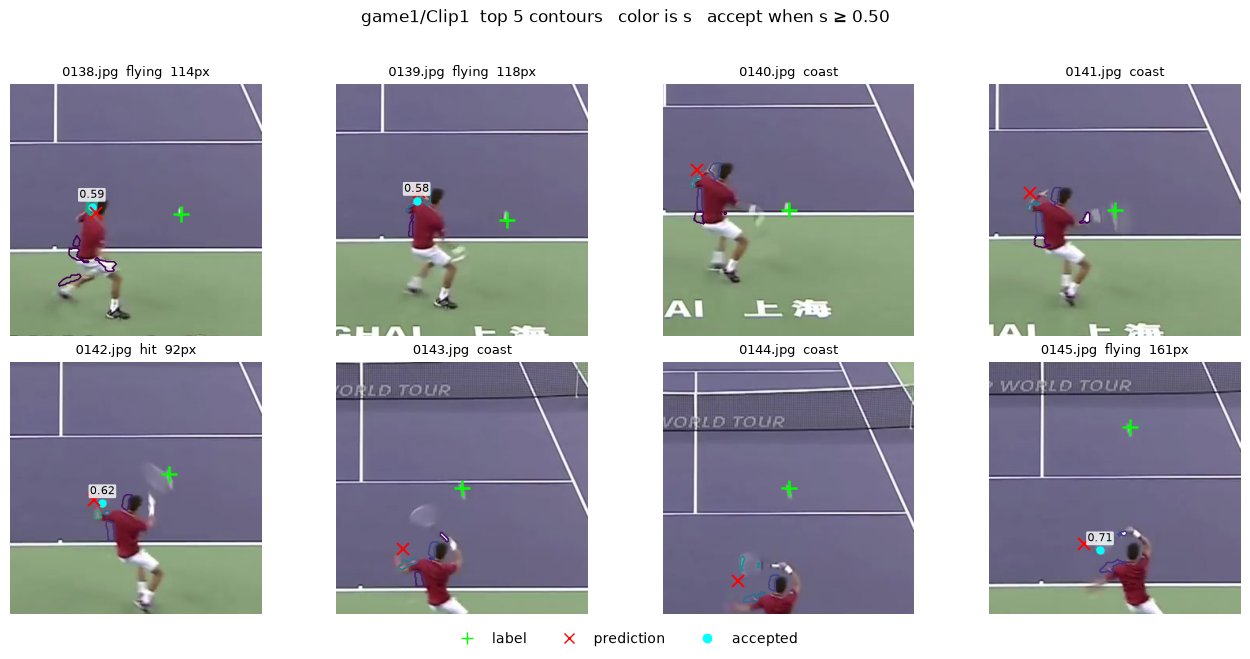

In [2]:
from matplotlib.cm import viridis
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon

HALF = 160
ncols = 4
nrows = int(np.ceil(COUNT / ncols))
norm = Normalize(0, 1)
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))


def crop(img, xy, half):
    h, w = img.shape[:2]
    if xy is None:
        xy = np.array([w / 2, h / 2], dtype=np.float64)
    x, y = int(round(float(xy[0]))), int(round(float(xy[1])))
    x0, x1 = max(0, x - half), min(w, x + half)
    y0, y1 = max(0, y - half), min(h, y + half)
    return img[y0:y1, x0:x1], (x0, y0)


for ax, i in zip(np.atleast_1d(axes).ravel(), window):
    frame, step = clip[i], steps[i]
    xy = frame["xy"]
    if xy is not None and step["xy"] is not None:
        center = 0.5 * (xy + step["xy"])
    elif xy is not None:
        center = xy
    else:
        center = step["xy"] if step["xy"] is not None else step["pred"]
    view, (x0, y0) = crop(cv2.cvtColor(step["bgr"], cv2.COLOR_BGR2RGB), center, HALF)
    ax.imshow(view)
    for blob, parts in step["shown"]:
        pts = blob.contour.reshape(-1, 2).astype(np.float64)
        pts[:, 0] -= x0
        pts[:, 1] -= y0
        accepted = step["accepted"] is blob
        ax.add_patch(
            Polygon(
                pts,
                closed=True,
                fill=False,
                edgecolor=viridis(norm(parts["s"])),
                lw=2.2 if accepted else 1.1,
            )
        )
    if step["accepted"] is not None:
        ax.plot(step["xy"][0] - x0, step["xy"][1] - y0, "o", color="cyan", ms=5)
        ax.text(
            step["xy"][0] - x0,
            step["xy"][1] - y0 - 8,
            f"{step['s']:.2f}",
            color="black",
            fontsize=8,
            ha="center",
            va="bottom",
            clip_on=True,
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8),
        )
    if step["pred"] is not None:
        ax.plot(step["pred"][0] - x0, step["pred"][1] - y0, "x", color="red", ms=8, mew=1.4)
    if frame["xy"] is not None:
        ax.plot(frame["xy"][0] - x0, frame["xy"][1] - y0, "+", color="lime", ms=11, mew=1.8)
    ax.set_xlim(0, view.shape[1])
    ax.set_ylim(view.shape[0], 0)
    title = frame["file"]
    if step["xy"] is not None and frame["xy"] is not None:
        err = float(np.linalg.norm(step["xy"] - frame["xy"]))
        title += f"  {MOVEMENT[frame['status']]}  {err:.0f}px"
    elif step["xy"] is None:
        title += "  coast"
    ax.set_title(title, fontsize=9)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[COUNT:]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label"),
        Line2D([0], [0], marker="x", color="red", lw=0, ms=7, label="prediction"),
        Line2D([0], [0], marker="o", color="cyan", lw=0, ms=6, label="accepted"),
    ],
    loc="lower center",
    ncol=3,
    frameon=False,
)
fig.suptitle(
    f"{GAME}/{CLIP}  top {TOP} contours   color is s   accept when s ≥ {ACCEPT:.2f}",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()


In [3]:
errs, hit, visibility, movement = [], [], [], []
absent = false = 0
for game in cfg["splits"]["test"]:
    game_dir = Path(cfg["paths"]["dataset"]) / game
    for clip_dir in sorted(p for p in game_dir.iterdir() if p.is_dir()):
        frames = load_clip(game, clip_dir.name)
        traced = detect(frames)
        for frame, step in zip(frames, traced):
            if step["n"] is None:
                continue
            xy = frame["xy"]
            if xy is None:
                absent += 1
                if step["xy"] is not None:
                    false += 1
                continue
            accepted = step["xy"] is not None
            hit.append(accepted)
            errs.append(float(np.linalg.norm(step["xy"] - xy)) if accepted else np.nan)
            visibility.append(frame["visibility"])
            movement.append(frame["status"])

errs = np.asarray(errs)
hit = np.asarray(hit)
visibility = np.asarray(visibility)
movement = np.asarray(movement)


def show_group(name: str, mask: np.ndarray) -> None:
    count = int(mask.sum())
    if count == 0:
        return
    dist = errs[mask]
    dist = dist[np.isfinite(dist)]
    dist_txt = f"{dist.mean():6.1f}" if len(dist) else "     —"
    print(
        f"{name:16}  n={count:5d}  "
        f"dist={dist_txt}  "
        f"hit={hit[mask].mean():.3f}"
    )


print("test  dist = accepted centroid vs label (px)  hit = fraction accepted")
show_group("all", np.ones(len(errs), dtype=bool))
print("movement")
for code, name in MOVEMENT.items():
    show_group(f"  {name}", movement == code)
print("obscurity")
print(f"{'  not in frame':16}  n={absent:5d}  false={false:5d}  accepted with no label")
for code, name in VISIBILITY.items():
    if code == 0:
        continue
    show_group(f"  {name}", visibility == code)


test  dist = accepted centroid vs label (px)  hit = fraction accepted
all               n= 2070  dist= 278.3  hit=0.513
movement
  flying          n= 1964  dist= 278.5  hit=0.513
  hit             n=   48  dist= 264.1  hit=0.521
  bouncing        n=   58  dist= 282.6  hit=0.500
obscurity
  not in frame    n=   62  false=   27  accepted with no label
  visible         n= 1885  dist= 270.0  hit=0.506
  hard to see     n=  184  dist= 351.4  hit=0.587
  occluded        n=    1  dist=     —  hit=0.000
